# DS2002 · Visualization Challenge

**Lab — 2026-11-13 · Fall 2026**  

---

## Lab 11 — Visualization Challenge

Five charts from the **same game-day sample** as Monday's lecture. Each one is graded against the **six-point rubric** from Wednesday's studio — use `score()` from that notebook or re-type it here.

| # | Criterion |
|---|---|
| 1 | Title states a finding, not a topic |
| 2 | Axes labeled with units |
| 3 | Right chart type for the question |
| 4 | Honest scale |
| 5 | Readable — sorted, no clipping, no overlap |
| 6 | No wasted ink |

Every chart needs a one-line **caption** below it saying what decision it supports.

**Due Wednesday, November 18, 11:59pm ET** in Canvas (pushed back one week for midterm presentations). Use Monday's recipes (`barh`, `lineplot`, `histplot`, `finish()`, etc.) — you do not need new chart types beyond what the cookbook already showed.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'
sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

CRITERIA = [
    'title states a finding',
    'axes labeled with units',
    'right chart for the question',
    'honest scale',
    'readable',
    'no wasted ink',
]

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total


def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """Same helper as Monday's lecture: title, labels, spines, tight_layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()


# --- game-day sample (same generator as the Monday lecture) ------------------
rng = np.random.default_rng(2026)
hours = np.arange(9, 22)
build_up = np.exp(-((hours - 14.5) ** 2) / (2 * 2.3 ** 2))
storm = np.exp(-((hours - 17.0) ** 2) / (2 * 1.5 ** 2))
GAMES = {'Sep 5': False, 'Sep 19': False, 'Oct 10': True, 'Nov 14': True}

rows = []
for game, rainy in GAMES.items():
    rain_mm = rainy * (0.4 + 3.0 * storm) * rng.gamma(10, 0.1, len(hours))
    for h, b, rain in zip(hours, build_up, rain_mm):
        n_main = rng.poisson(b * 150 + 12)
        n_rain = rng.poisson(rain * 5 + 0.2)
        cats = np.concatenate([
            rng.choice(['Food', 'Merch', 'Drink'], n_main, p=[.45, .22, .33]),
            np.repeat('RainGear', n_rain),
        ])
        rows += [(game, 'rain' if rainy else 'dry', h, round(rain, 1), c) for c in cats]

df = pd.DataFrame(rows, columns=['game', 'weather', 'hour', 'rain_mm', 'category'])
df['zone'] = rng.choice(['A', 'B', 'C'], len(df), p=[.6, .3, .1])
df['revenue'] = (
    df['category'].map({'Food': 12, 'Merch': 28, 'Drink': 6, 'RainGear': 15})
    * rng.lognormal(-0.18, 0.6, len(df))
).round(2)

print(len(df), 'orders across', df['game'].nunique(), 'games')
df.head()


4364 orders across 4 games


,game,weather,hour,rain_mm,category,zone,revenue
0,Sep 5,dry,9,0.0,Food,C,7.90
1,Sep 5,dry,9,0.0,Food,B,5.46
2,Sep 5,dry,9,0.0,Drink,A,7.93
3,Sep 5,dry,9,0.0,Drink,B,5.68
4,Sep 5,dry,9,0.0,Merch,A,12.75


In [2]:
df['game'].unique()

array(['Sep 5', 'Sep 19', 'Oct 10', 'Nov 14'], dtype=object)

### Chart 1 — revenue by category

Sorted horizontal bar. Axis from zero.

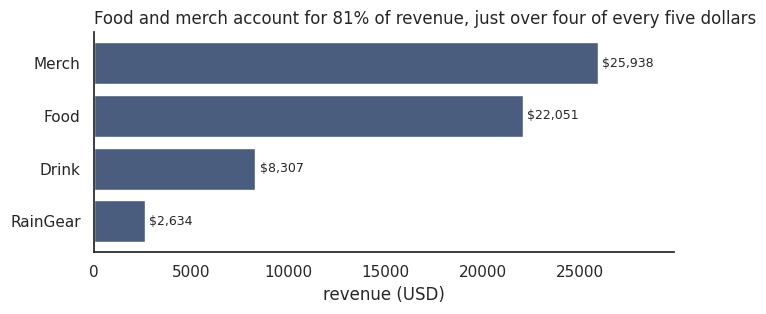

In [3]:
# TODO
totals = df.groupby("category")["revenue"].sum().sort_values()

fig, ax = plt.subplots(figsize=(7, 3.3))
bars = ax.barh(totals.index, totals.values, color=BLUE)
ax.bar_label(bars, labels=[f'${v:,.0f}' for v in totals.values], padding=3, fontsize=9)
ax.set_xlim(0, totals.max() * 1.15)
share = (totals['Food'] + totals['Merch']) / totals.sum()
finish(ax, f'Food and merch account for {share:.0%} of revenue, just over four of every five dollars', xlabel='revenue (USD)')
plt.show()

**Caption:** It is crucial to have a large stock of merch and food, as they are huge revenue leaders and potential revenue will be lost if the items are not available.

### Chart 2 — revenue by hour

Line chart, kickoff marked at 15.5, and the title should state the staffing implication rather than describing the axes.

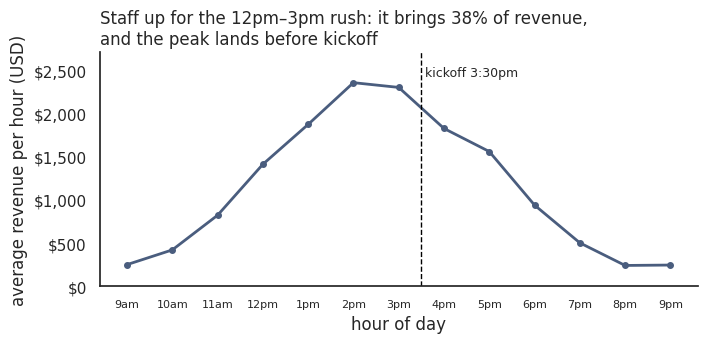

In [4]:
# TODO

n_games = df['game'].nunique()
hourly = (df.groupby('hour')['revenue'].sum() / n_games).reindex(range(9, 22), fill_value=0)

def clock(h):
    return f'{(h - 1) % 12 + 1}{"am" if h < 12 else "pm"}'

# fixed rush window: 12pm-3pm = hour buckets 12, 13, 14
a, b = 12, 14
share = hourly.loc[a:b].sum() / hourly.sum()
peak = hourly.idxmax()
rel = 'before' if peak + 0.5 < 15.5 else 'after'

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(hourly.index, hourly.values, color=BLUE, lw=2, marker='o', ms=4)
ax.axvline(15.5, color='black', lw=1, ls='--')
ax.text(15.5, hourly.max() * 1.02, ' kickoff 3:30pm', ha='left', va='bottom', fontsize=9)

ax.set_ylim(0, hourly.max() * 1.15)
ax.set_xticks(hourly.index, [clock(h) for h in hourly.index], fontsize=8)
ax.yaxis.set_major_formatter(lambda v, _: f'${v:,.0f}')

finish(ax, f'Staff up for the {clock(a)}–{clock(b + 1)} rush: it brings {share:.0%} of revenue,\n'
           f'and the peak lands {rel} kickoff',
       xlabel='hour of day')
ax.set_ylabel('average revenue per hour (USD)')
plt.show()

**Caption:** Supports the decision to have the most amount of staff peaking around 12pm, as the next 3 hours lead up to peak purchasing from customers.

### Chart 3 — revenue by zone, normalized

Raw revenue by zone mostly measures how big each zone is. Use the capacity figures below to build a second view — revenue per unit of capacity — and show both side by side.

Then say which of the two you would put in front of a manager, and for which question.

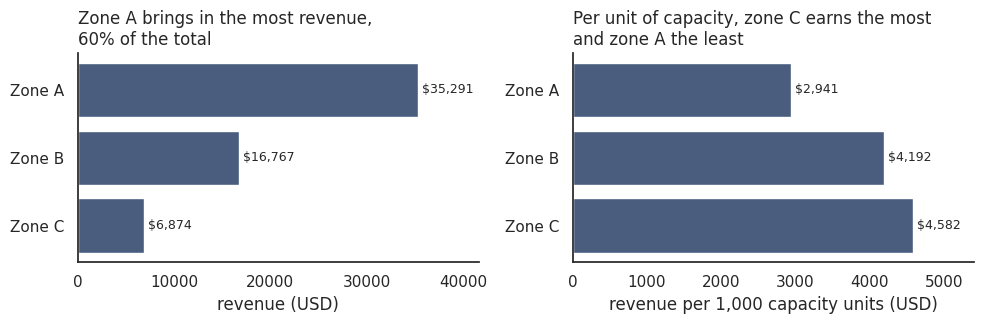

In [5]:
zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}
# TODO: two panels -- raw revenue and revenue per capacity

zones = list(zone_capacity)
cap = pd.Series(zone_capacity)

raw = df.groupby('zone')['revenue'].sum().reindex(zones)
per_k = raw / cap * 1000                         # USD per 1,000 capacity units

top_raw = raw.idxmax()
top_per, low_per = per_k.idxmax(), per_k.idxmin()
raw_share = raw[top_raw] / raw.sum()
cap_share = cap[top_raw] / cap.sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))

# Panel 1: raw revenue
bars = ax1.barh([f'Zone {z}' for z in zones], raw.values, color=BLUE)
ax1.bar_label(bars, labels=[f'${v:,.0f}' for v in raw.values], padding=3, fontsize=9)
ax1.set_xlim(0, raw.max() * 1.18)
ax1.invert_yaxis()                               # keep A, B, C top to bottom
finish(ax1, f'Zone {top_raw} brings in the most revenue,\n{raw_share:.0%} of the total',
       xlabel='revenue (USD)')

# Panel 2: revenue per unit of capacity
bars = ax2.barh([f'Zone {z}' for z in zones], per_k.values, color=BLUE)
ax2.bar_label(bars, labels=[f'${v:,.0f}' for v in per_k.values], padding=3, fontsize=9)
ax2.set_xlim(0, per_k.max() * 1.18)
ax2.invert_yaxis()
finish(ax2, f'Per unit of capacity, zone {top_per} earns the most\nand zone {low_per} the least',
       xlabel='revenue per 1,000 capacity units (USD)')

plt.tight_layout()
plt.show()

**Caption, and which panel I would present:** I would present the panel on the right, as it gives a more realistic picture of what the data is telling us, that being that Zone C is the most dense in terms of revenue generation. The data supports a decision to model zones A and B similar to zone C.

### Chart 4 — distribution, not just totals

Every chart so far is a total. **TODO:** show the *distribution* of individual order revenue with a histogram. What does the shape tell you that a category total does not?

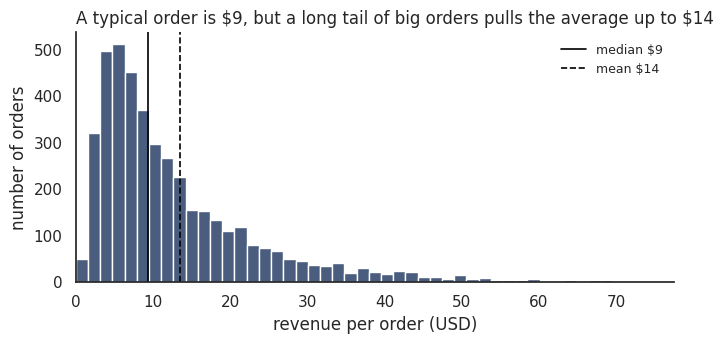

In [6]:
# TODO

rev = df['revenue']
xmax = rev.quantile(0.995)                      # trim extreme tail so the bulk is readable
bins = np.linspace(0, xmax, 50)
median, mean = rev.median(), rev.mean()

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(rev, bins=bins, color=BLUE, edgecolor='white', lw=0.5)
ax.axvline(median, color='black', lw=1.2, label=f'median ${median:.0f}')
ax.axvline(mean, color='black', lw=1.2, ls='--', label=f'mean ${mean:.0f}')
ax.set_xlim(0, xmax)
ax.legend(frameon=False, fontsize=9, loc='upper right')

finish(ax, f'A typical order is ${median:.0f}, but a long tail of big orders pulls the average up to ${mean:.0f}',
       xlabel='revenue per order (USD)')
ax.set_ylabel('number of orders')
fig.tight_layout()
plt.show()

**Caption:** The venue may want to look at self-checkout lines in order to speed up line wait times, as a large distriubution of the purchases are small purchases. Providing customers a way to avoid longer lines for small purchases may lead to better perception.

### Chart 5 — your choice

**TODO:** a grouped, stacked, or scatter view that reveals something the first four do not. The finding is the point; the chart type is your call.

If you use a scatter, size or annotate the points so a reader can tell which ones carry enough data to trust.

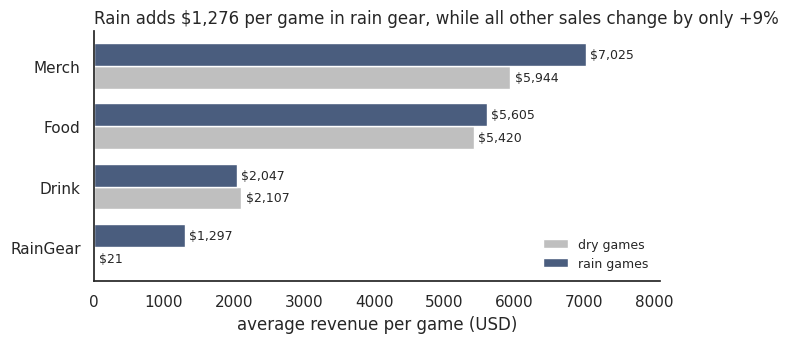

In [7]:
# TODO
# average revenue per game, by category and weather
per_game = (df.groupby(['weather', 'game', 'category'])['revenue'].sum()
              .unstack('category', fill_value=0))
avg = per_game.groupby('weather').mean().T          # rows: category, cols: dry / rain
avg = avg.sort_values('rain')                       # same sorted-bar logic as Chart 1

rg_add = avg.loc['RainGear', 'rain'] - avg.loc['RainGear', 'dry']
other = avg.drop('RainGear')
other_chg = other['rain'].sum() / other['dry'].sum() - 1

fig, ax = plt.subplots(figsize=(7, 3.6))
y = np.arange(len(avg))
h = 0.38
b_dry = ax.barh(y - h/2, avg['dry'], height=h, color='0.75', label='dry games')
b_rain = ax.barh(y + h/2, avg['rain'], height=h, color=BLUE, label='rain games')
ax.bar_label(b_dry, labels=[f'${v:,.0f}' for v in avg['dry']], padding=3, fontsize=9)
ax.bar_label(b_rain, labels=[f'${v:,.0f}' for v in avg['rain']], padding=3, fontsize=9)

ax.set_yticks(y, avg.index)
ax.set_xlim(0, avg.values.max() * 1.15)
ax.legend(frameon=False, fontsize=9, loc='lower right')

finish(ax, f'Rain adds ${rg_add:,.0f} per game in rain gear, while all other sales change by only {other_chg:+.0%}',
       xlabel='average revenue per game (USD)')
plt.show()

**Caption:** Supports the decision to not have a large stock of rain gear on days with dry forecasted weather.

### Score your own work

**TODO:** score each chart out of 6 and fix anything under 5 before submitting.

In [9]:
scores = {
    'chart 1 (category)': 6,     # TODO: out of 6
    'chart 2 (hour)': 6,
    'chart 3 (zone)': 6,
    'chart 4 (distribution)': 6,
    'chart 5 (your choice)': 6,
}

for name, s in scores.items():
    status = 'unscored' if s is None else ('fix' if s < 5 else 'ok')
    print(f'{name:<26} {s}/6  [{status}]')

filled = [s for s in scores.values() if s is not None]
if filled:
    print(f'\naverage: {sum(filled) / len(filled):.1f}/6')

chart 1 (category)         6/6  [ok]
chart 2 (hour)             6/6  [ok]
chart 3 (zone)             6/6  [ok]
chart 4 (distribution)     6/6  [ok]
chart 5 (your choice)      6/6  [ok]

average: 6.0/6


### Write-up

**a)** Which chart changed your mind about something in the data? If none did, which was hardest to title, and why?

**b)** Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.

A) None of the charts really changed my mind about the data, but chart 2 (revenue by hour) was probably the hardest to title. I found it a bit difficult because choosing the window in which to define the "peak purchasing" was subjective. It would be easy to just say that from when the gates open until kickoff should be seen as the "peak", but that ignores the incremental nature of the data. This time frame would show a bigger percent of purchases, but it would likely result in unused staff in the early hours of operation.

B) You likely need to show raw revenue in an accounting-like situiation where the question is purely "where is the money coming from". Comparing the raw revenue and the normalized revenue would also give insights into potential changes that can be made in the design of high revenue, low normalized zones. Because the normalized revenue can answer a question such as "which zone elicits the most purchasing from its consumers", if a zone that recieves a lot of revenue at a low normalized rate adopts practices from a denser purchasing zone, said zone could experience significant revenue gains.